# Spent (17 hrs, 30 ˚C) Vs unspent (3 hrs, 37 ˚C) EsaR data analysis

## Setup

In [ ]:
try:
    import cdk
    print("CDK already installed, skipping installation and restart.")
except ImportError:
    !pip install nucleus-cdk -q > /dev/null 2>&1
    print("\nInstallation complete. Restarting runtime to refresh dependencies...")
    import os
    os._exit(0)

CDK already installed, skipping installation and restart.


In [ ]:

import pandas as pd
pd.set_option('display.max_columns', None)
import seaborn as sns
import matplotlib.pyplot as plt

# Import the cdk platereader module
from cdk.instruments import platereader as pr

from cdk import logging
log = logging.setup_logging(logging.ERROR)

## Load Data

In [ ]:
%%writefile drive_utils.py
import os
import re

import gdown


def get_drive_file_id(url):
    """Extract the file ID from a Google Drive share URL."""
    match = re.search(r'/d/([a-zA-Z0-9_-]+)', url)
    if match:
        return match.group(1)
    return None


def download_from_drive(files_info, destination_dir):
    """
    Download files from Google Drive.

    Args:
        files_info (list): List of dicts with 'url' and 'filename'.
        destination_dir (str): Local path to save files.
    Returns:
        dict: Mapping of filenames to local paths.
    """
    os.makedirs(destination_dir, exist_ok=True)

    paths = {}
    for item in files_info:
        url = item['url']
        filename = item['filename']
        dest = os.path.join(destination_dir, filename)
        file_id = get_drive_file_id(url)

        if file_id:
            gdown.download(id=file_id, output=dest, quiet=True)
        else:
            gdown.download(url, output=dest, quiet=True)

        paths[filename] = dest
    return paths

Writing drive_utils.py


In [ ]:
# Set use_drive = True to download data_file and platemap_file from Google Drive instead of
# using local files. Each Drive file must have its permissions set to "Anyone with a link" can "view".
use_drive = True

if use_drive:
    from drive_utils import download_from_drive

    files_to_download = [
        {
            "url": "https://drive.google.com/file/d/1oB_drvnZlumdGA3YeNzLriyyOfpD0Tf2/view?usp=share_link",  # Replace with your data file link.
            "filename": "raw_data.txt",
        },
        {
            "url": "https://drive.google.com/file/d/1puOwaq-1GdhuBzcRYbKtwzQFE7NpIVrB/view?usp=share_link",  # Replace with your platemap file link.
            "filename": "platemap.csv",
        },

        {
        "url": "https://drive.google.com/file/d/1N0TNkgjd5q_a_nTgVgA4pad-nc-dUELW/view?usp=share_link",  # normalized_samples_only.csv from the 2026-09-25 DNA titration run, for cross-day comparison.
    "filename": "normalized_samples_only.csv",
        }
    ]
    downloaded_paths = download_from_drive(files_to_download, destination_dir="data")
    data_file = downloaded_paths["raw_data.txt"]
    platemap_file = downloaded_paths["platemap.csv"]
else:
    data_file = "sample-data/20251111-122213-cytation5-pure-timecourse-gfp-MFG-98-tRNA-QC.txt"
    platemap_file = "sample-data/platemap.csv"

print(f"Data file: {data_file}\nPlatemap file: {platemap_file}")

Data file: data/raw_data.txt
Platemap file: data/platemap.csv


In [ ]:
# Load data
result = pr.load_platereader_data(
    data_file=data_file,
    platemap_file=platemap_file,
    platereader="biotek" # options: "biotek"
)

The output is a list of `PlateReaderResult` objects; if you did more than one read on the plate reader, the results will be in separate objects.

In [ ]:
print(result)

PlateReaderResult with the following 3 blocks:
0: (2117, 50) kinetic read with reads: GFP-G50:485/20,528/20 (Fluorescence) (Plate 'Plate 1')
1: (2117, 50) kinetic read with reads: GFP-G35:485/20,528/20 (Fluorescence) (Plate 'Plate 1')
2: (348, 48) endpoint read with reads: Max V [GFP-G50:485/20,528/20] (Fluorescence), R-Squared [GFP-G50:485/20,528/20] (Fluorescence), t at Max V [GFP-G50:485/20,528/20] (Fluorescence), Lagtime [GFP-G50:485/20,528/20] (Fluorescence), Max V [GFP-G35:485/20,528/20] (Fluorescence), R-Squared [GFP-G35:485/20,528/20] (Fluorescence), t at Max V [GFP-G35:485/20,528/20] (Fluorescence), Lagtime [GFP-G35:485/20,528/20] (Fluorescence), Count (None), Mean (None), Std Dev (None), CV (%) (None) (Plate 'Plate 1')


Here there were two reads with different gains but the same excitation/emission spectrum, on one plate. If we want just the `GFP-Gext` read, this corresponds to block index 1, so we can extract that block by indexing:

In [ ]:
desired_index = 1
data = result[desired_index]

You can see the underlying data with `data.view()` (which returns a Pandas DataFrame):

In [ ]:
data.view().head()

,Date,Experiment,Well,Name,Type,Time,Data,Read,Read Name,Reader Type,Reader ID,Plate Type,Plate ID,Start Time,Read Modality,Gain,Excitation Wavelength (nm),Excitation Bandwidth (nm),Excitation Optics,Emission Wavelength (nm),Emission Bandwidth (nm),Emission Optics,Read Geometry,Read Height (mm),Rxn Volume (uL),Construct,Small Molecule Mix Vol (uL),tRNA Vol (uL),Protein Mix Vol (uL),Ribosomes Vol (uL),RNase Inhibitor Vol (uL),DNA Template Vol (uL),EsaR Vol (uL),AHSL Vol (uL),Water Vol (uL),[DNA Template] (ng/uL),DNA Template (nM),[AHSL] (uM),[Fluorescein] (uM)
0,2026-09-26,[EsaO]2-mNG DNA titration +/- AHSL with pre-ex...,B2,mNG control (15.6 nM),Sample,0 days 00:00:31,4,"GFP-G35:485/20,528/20",GFP-G35,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-26 11:54:05,Fluorescence,35,485,20,filter,528,20,filter,Top 510 nm,7 mm,10,mNG,3.0314,1.0,1.2,1.8171,0.2514,0.4743,0.0,0.0,2.2257,NaN,NaN,0,0.0
1,2026-09-26,[EsaO]2-mNG DNA titration +/- AHSL with pre-ex...,B2,mNG control (15.6 nM),Sample,0 days 00:05:31,3,"GFP-G35:485/20,528/20",GFP-G35,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-26 11:54:05,Fluorescence,35,485,20,filter,528,20,filter,Top 510 nm,7 mm,10,mNG,3.0314,1.0,1.2,1.8171,0.2514,0.4743,0.0,0.0,2.2257,NaN,NaN,0,0.0
2,2026-09-26,[EsaO]2-mNG DNA titration +/- AHSL with pre-ex...,B2,mNG control (15.6 nM),Sample,0 days 00:10:31,12,"GFP-G35:485/20,528/20",GFP-G35,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-26 11:54:05,Fluorescence,35,485,20,filter,528,20,filter,Top 510 nm,7 mm,10,mNG,3.0314,1.0,1.2,1.8171,0.2514,0.4743,0.0,0.0,2.2257,NaN,NaN,0,0.0
3,2026-09-26,[EsaO]2-mNG DNA titration +/- AHSL with pre-ex...,B2,mNG control (15.6 nM),Sample,0 days 00:15:31,162,"GFP-G35:485/20,528/20",GFP-G35,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-26 11:54:05,Fluorescence,35,485,20,filter,528,20,filter,Top 510 nm,7 mm,10,mNG,3.0314,1.0,1.2,1.8171,0.2514,0.4743,0.0,0.0,2.2257,NaN,NaN,0,0.0
4,2026-09-26,[EsaO]2-mNG DNA titration +/- AHSL with pre-ex...,B2,mNG control (15.6 nM),Sample,0 days 00:20:31,477,"GFP-G35:485/20,528/20",GFP-G35,Synergy 2,206621,Greiner 384 SV NoBind Automap,Plate 1,2026-09-26 11:54:05,Fluorescence,35,485,20,filter,528,20,filter,Top 510 nm,7 mm,10,mNG,3.0314,1.0,1.2,1.8171,0.2514,0.4743,0.0,0.0,2.2257,NaN,NaN,0,0.0


## Plot Raw Curves

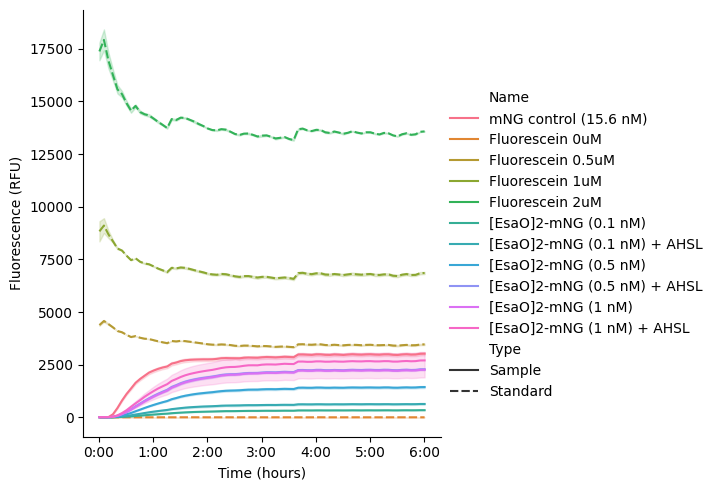

In [ ]:
data.plot(style='Type')

## Plotting selected timecourse data

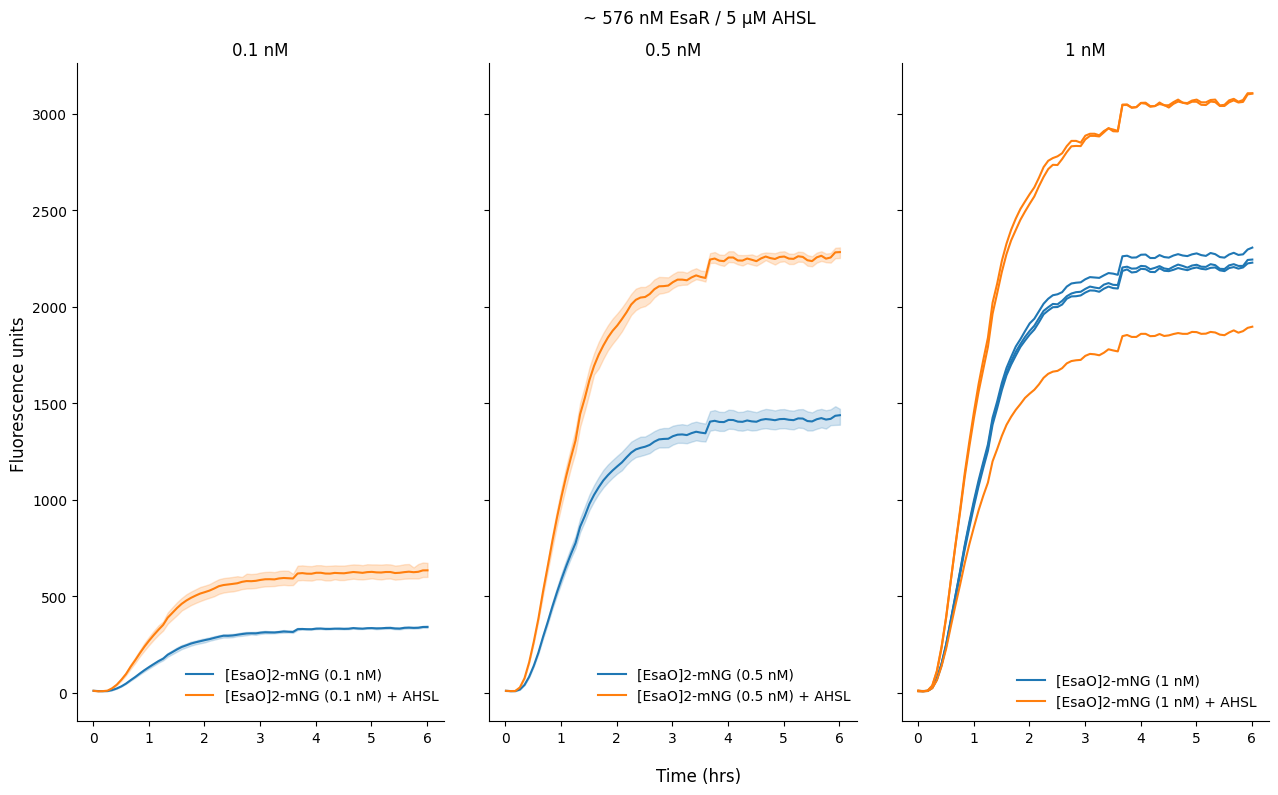

In [ ]:
data_EsaO2_01 = data.select(name=["[EsaO]2-mNG (0.1 nM)", "[EsaO]2-mNG (0.1 nM) + AHSL"])
data_EsaO2_05 = data.select(name=["[EsaO]2-mNG (0.5 nM)", "[EsaO]2-mNG (0.5 nM) + AHSL"])
data_EsaO2_1 = data.select(name=["[EsaO]2-mNG (1 nM)", "[EsaO]2-mNG (1 nM) + AHSL"])

df_1 = data_EsaO2_01.data
df_2 = data_EsaO2_05.data
df_3 = data_EsaO2_1.data


# convert timedelta -> float hours
for df in (df_1, df_2, df_3):
    df['Time_hrs'] = df['Time'].dt.total_seconds() / 3600

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13,8), sharey=True)
fig.suptitle('~ 576 nM EsaR / 5 µM AHSL', x=0.55)

sns.lineplot(data=df_1, x='Time_hrs', y='Data', hue='Name', ax=ax1)
sns.lineplot(data=df_2, x='Time_hrs', y='Data', hue='Name', ax=ax2)
sns.lineplot(data=df_3, x='Time_hrs', y='Data', hue='Name', ax=ax3, units='Well', estimator=None)

ax1.set(title='0.1 nM', ylabel='', xlabel='')
ax2.set(title='0.5 nM', ylabel='', xlabel='')
ax3.set(title='1 nM', ylabel='', xlabel='')

fig.supxlabel('Time (hrs)', x=0.55)
fig.supylabel('Fluorescence units')

for ax in (ax1, ax2, ax3):
    ax.legend(frameon=False)

ax1.legend(loc='upper center', bbox_to_anchor=(0.64, 0.1), frameon=False)
ax2.legend(loc='upper center', bbox_to_anchor=(0.64, 0.1), frameon=False)


sns.despine(fig)
fig.tight_layout()

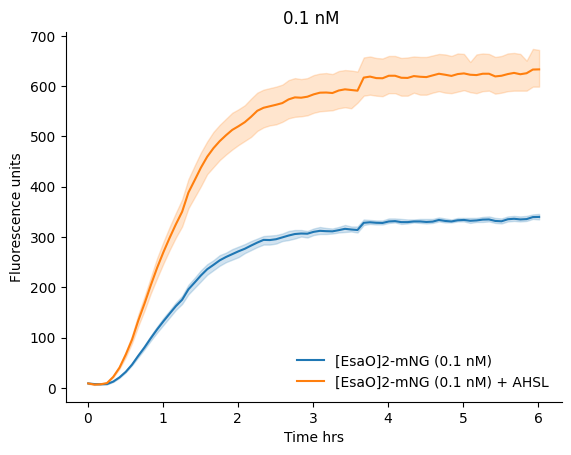

In [ ]:
sns.lineplot(data=df_1, x='Time_hrs', y='Data', hue='Name')

plt.title("0.1 nM ")
plt.xlabel("Time hrs")
plt.ylabel("Fluorescence units")
plt.legend(frameon=False)
sns.despine()




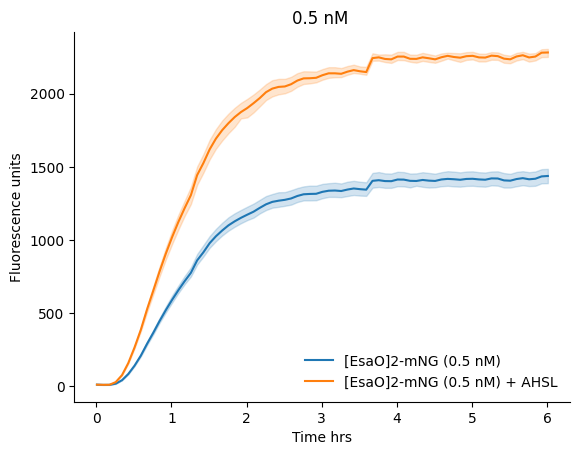

In [ ]:
sns.lineplot(data=df_2, x='Time_hrs', y='Data', hue='Name')

plt.title("0.5 nM ")
plt.xlabel("Time hrs")
plt.ylabel("Fluorescence units")
plt.legend(frameon=False)
sns.despine()


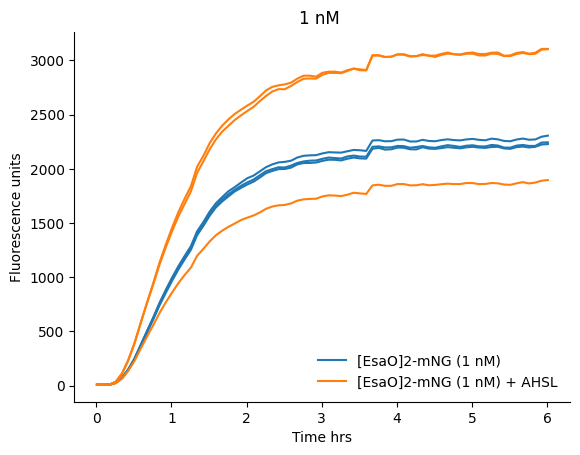

In [ ]:
sns.lineplot(data=df_3, x='Time_hrs', y='Data', hue='Name', units="Well", estimator = None)

plt.title("1 nM ")
plt.xlabel("Time hrs")
plt.ylabel("Fluorescence units")
plt.legend(frameon=False)
sns.despine()

We can see that the standard (here, HPTS) is stable and can be safely used for normalization.

## Normalize Data
Now, use `data.normalize('<standard name>')` to normalize your data. This will calculate the average over a time window at the end of the experiment (by default, 1 hour), then divide all data by the mean of that window-average across all wells with the same `Name` (defined by your platemap).

In [ ]:
# To check the exact name of your standard
platemap = data.platemap
standards = platemap[platemap['Type']=='Standard']
standards['Name'].unique()

array(['Fluorescein 0uM', 'Fluorescein 0.5uM', 'Fluorescein 1uM',
       'Fluorescein 2uM'], dtype=object)

In [ ]:
data = data.normalize('Fluorescein 0.5uM')

Now replot your curves to see them normalized:

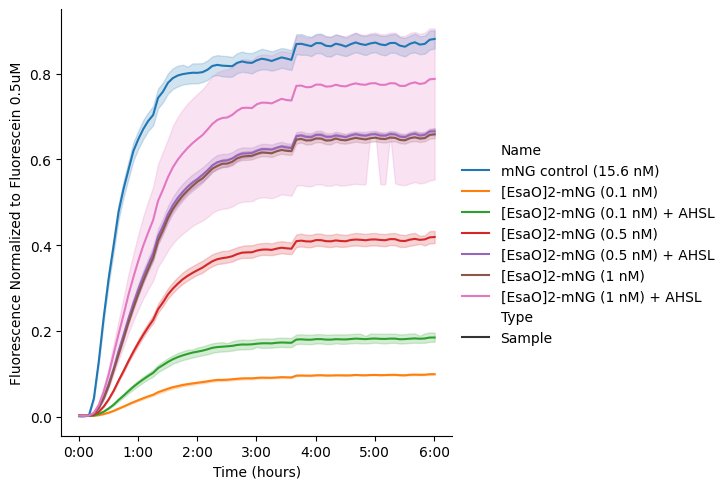

In [ ]:
g = data.plot(style='Type', exclude_types=['Standard'])
# g.savefig('after-normalization.png',dpi=300)

## Export current data to plot comparison with unspent EsaR data

In [ ]:
# Get the normalized view of the current data
df_current_norm = data.normalize('Fluorescein 0.5uM').view().copy()

# Filter out standards to keep only the experimental samples
df_current_samples_only = df_current_norm[df_current_norm['Type'] != 'Standard']

# Export to a CSV file
output_filename = 'normalized_current_run.csv'
df_current_samples_only.to_csv(output_filename, index=False)
print(f"Successfully exported normalized samples to {output_filename}")

Successfully exported normalized samples to normalized_current_run.csv


## Plot comparison (spent Vs unspent) summary plot

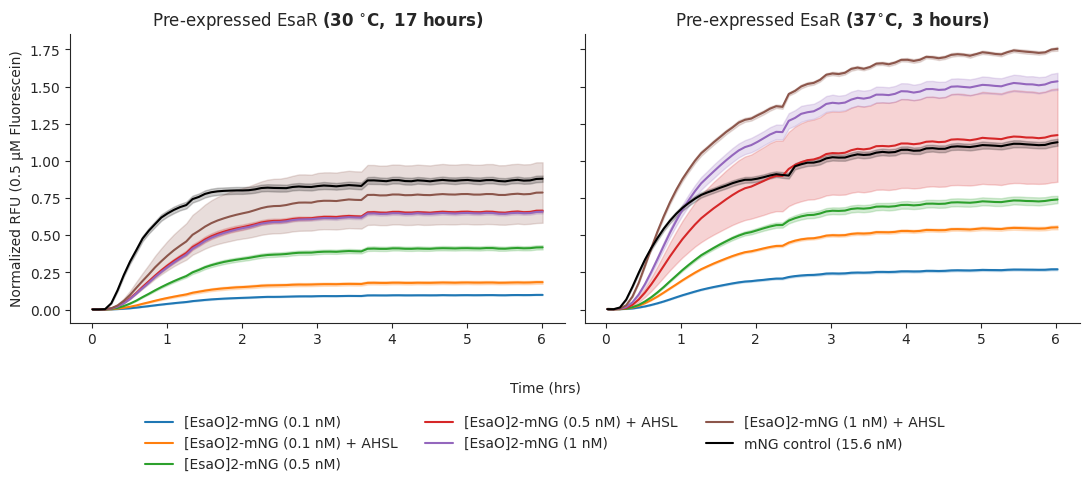

In [ ]:


#!/usr/bin/env python3
"""
Side-by-side plate-reader kinetics with a shared y-axis (seaborn).

Edit the CONFIG block below, then run:
    python plot_panels_seaborn.py
"""
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# =============================================================================
# CONFIG — edit these
# =============================================================================

# One dict per panel, left -> right.
#   file    : CSV path
#   title   : panel title (mathtext $\mathbf{...}$ makes that part bold)
#   include : substring(s) a sample Name must contain to be plotted (None = all)
#   exclude : substring(s) that drop a sample Name (None = nothing dropped)
#   extra   : exact sample Name(s) to add on top of `include` (e.g. the "mNG control (15.6 nM)" control)
PANELS = [
    dict(file="normalized_current_run.csv",
         title=r"Pre-expressed EsaR $\mathbf{(30\ ^{\circ}C,\ 17\ hours)}$",
         include=["[EsaO]2-mNG"], exclude=None, extra=["mNG control (15.6 nM)"]),
    dict(file="data/normalized_samples_only.csv",
         title=r"Pre-expressed EsaR $\mathbf{(37^{\circ}C,\ 3\ hours)}$",
         include=["[EsaO]2-mNG"], exclude=None, extra=["mNG control (15.6 nM)"]),
]

Y_LABEL = "Normalized RFU (0.5 µM Fluorescein)"
X_LABEL = "Time (hrs)"

# What to plot on y:
#   "normalized" -> Data_normalized (fluorescein-calibrated; comparable across days)
#   "raw"        -> raw counts (uses Data_raw if present, otherwise Data)
Y_DATA = "normalized"

# Line grouping. Any column of the CSV works, e.g. "Name", "DNA Template (nM)", "AHSL".
HUE = "Name"          # colour
STYLE = None          # line dash (e.g. "AHSL"); None = all solid
PALETTE = "tab10"     # seaborn palette name, or a list of colours
COLOR_OVERRIDES = {"mNG control (15.6 nM)": "black"}   # fix colours for specific hue values

ERRORBAR = "sd"       # "sd", ("ci", 95), "se", or None for no band
SHARE_Y = True
Y_LIM = None          # e.g. (0, 4500); None = auto
X_LIM = None          # e.g. (0, 6)

FIGSIZE = (11, 4.8)
# Legend placement:
#   "shared" -> one legend under the figure (best when there are many lines)
#   "each"   -> a legend inside every panel at LEGEND_LOC (like the reference plot)
LEGEND_MODE = "shared"
LEGEND_LOC = "lower right"   # used when LEGEND_MODE = "each"
LEGEND_NCOL = 3              # used when LEGEND_MODE = "shared"
LEGEND_FONTSIZE = 10

# Fonts — set to match the RFU figure (matplotlib defaults: DejaVu Sans, 10 pt base)
FONT_FAMILY = "DejaVu Sans"
TICK_FONTSIZE = 10
TITLE_FONTSIZE = 12          # panel titles
LABEL_FONTSIZE = 10          # x / y axis labels
OUTFILE = "panels_seaborn.png"
DPI = 200

# =============================================================================


def load_panel(cfg):
    df = pd.read_csv(cfg["file"])

    # Filter sample names
    keep = pd.Series(True, index=df.index)
    if cfg.get("include"):
        keep = df["Name"].apply(lambda n: any(s in n for s in cfg["include"]))
    if cfg.get("exclude"):
        keep &= ~df["Name"].apply(lambda n: any(s in n for s in cfg["exclude"]))
    if cfg.get("extra"):
        keep |= df["Name"].isin(cfg["extra"])
    df = df[keep].copy()

    # y column
    if Y_DATA == "raw":
        df["y"] = df["Data_raw"] if "Data_raw" in df.columns else df["Data"]
    else:
        df["y"] = df["Data_normalized"]

    # Time in hours, aligned across replicate wells (they are read seconds apart)
    df["hours_raw"] = pd.to_timedelta(df["Time"]).dt.total_seconds() / 3600
    df["read_idx"] = df.groupby("Well").cumcount()
    df["hours"] = df.groupby("read_idx")["hours_raw"].transform("mean")

    # Handy grouping column
    df["AHSL"] = df["[AHSL] (uM)"].fillna(0).gt(0).map({True: "+ AHSL", False: "– AHSL"})
    return df


def main():
    sns.set_style("ticks")
    # seaborn's style switches the font list to Arial-first; force the publication font
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": [FONT_FAMILY],
        "font.size": TICK_FONTSIZE,
        "xtick.labelsize": TICK_FONTSIZE,
        "ytick.labelsize": TICK_FONTSIZE,
        "mathtext.fontset": "dejavusans",
        # nothing bold by default: only the \mathbf{...} part of the panel titles
        "font.weight": "normal",
        "axes.titleweight": "normal",
        "axes.labelweight": "normal",
        "figure.titleweight": "normal",
        "figure.labelweight": "normal",
    })
    data = [load_panel(p) for p in PANELS]

    # Consistent colours across panels: one colour per hue value, shared by all panels
    hue_order = sorted(pd.concat(d[HUE] for d in data).unique(), key=str) if HUE else None
    if HUE:
        others = [h for h in hue_order if h not in COLOR_OVERRIDES]
        colors = dict(zip(others, sns.color_palette(PALETTE, len(others))))
        colors.update({h: c for h, c in COLOR_OVERRIDES.items() if h in hue_order})
    else:
        colors = None

    fig, axes = plt.subplots(1, len(PANELS), figsize=FIGSIZE, sharey=SHARE_Y, squeeze=False)
    axes = axes[0]

    for ax, cfg, df in zip(axes, PANELS, data):
        sns.lineplot(
            data=df, x="hours", y="y",
            hue=HUE, hue_order=[h for h in hue_order if h in set(df[HUE])] if HUE else None,
            palette=colors, style=STYLE,
            errorbar=ERRORBAR, ax=ax,
        )
        ax.set_title(cfg["title"], fontsize=TITLE_FONTSIZE, fontweight="normal")
        ax.set_xlabel("")
        ax.set_ylabel("")
        if X_LIM:
            ax.set_xlim(X_LIM)
        if ax.get_legend():
            if LEGEND_MODE == "each":
                sns.move_legend(ax, LEGEND_LOC, frameon=False, fontsize=LEGEND_FONTSIZE, title=None)
            else:
                ax.get_legend().remove()

    if Y_LIM:
        axes[0].set_ylim(Y_LIM)
    axes[0].set_ylabel(Y_LABEL, fontsize=LABEL_FONTSIZE, fontweight="normal")
    fig.supxlabel(X_LABEL, fontsize=LABEL_FONTSIZE, fontweight="normal")
    sns.despine(fig)

    if LEGEND_MODE == "shared" and (HUE or STYLE):
        # Collect unique entries across all panels
        seen = {}
        for ax in axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                seen.setdefault(l, h)
        fig.legend(seen.values(), seen.keys(), loc="lower center", ncol=LEGEND_NCOL,
                   frameon=False, fontsize=LEGEND_FONTSIZE, bbox_to_anchor=(0.5, -0.02))
        fig.tight_layout(rect=(0, 0.04 + 0.045 * -(-len(seen) // LEGEND_NCOL), 1, 1))
        fig.supxlabel(X_LABEL, fontsize=LABEL_FONTSIZE, fontweight="normal",
                      y=0.03 + 0.045 * -(-len(seen) // LEGEND_NCOL))
    else:
        fig.tight_layout()
    fig.savefig(OUTFILE, dpi=DPI, bbox_inches="tight")

if __name__ == "__main__":
    main()


## Plot comparison at 1 nM DNA

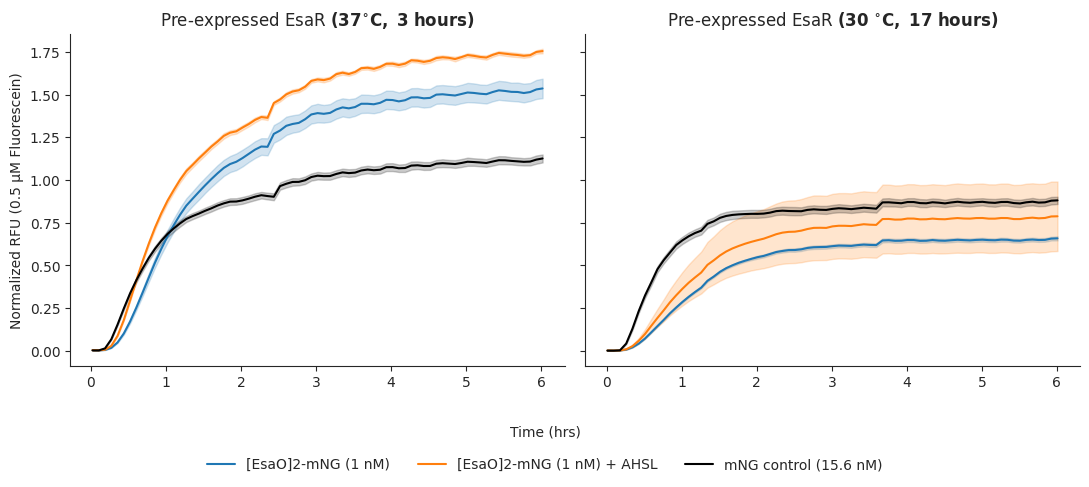

In [ ]:


#!/usr/bin/env python3
"""
Side-by-side plate-reader kinetics with a shared y-axis (seaborn).

Edit the CONFIG block below, then run:
    python plot_panels_seaborn.py
"""
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# =============================================================================
# CONFIG — edit these
# =============================================================================

# One dict per panel, left -> right.
#   file    : CSV path
#   title   : panel title (mathtext $\mathbf{...}$ makes that part bold)
#   include : substring(s) a sample Name must contain to be plotted (None = all)
#   exclude : substring(s) that drop a sample Name (None = nothing dropped)
#   extra   : exact sample Name(s) to add on top of `include` (e.g. the "mNG control (15.6 nM)" control)
PANELS = [
    dict(file="data/normalized_samples_only.csv",
         title=r"Pre-expressed EsaR $\mathbf{(37^{\circ}C,\ 3\ hours)}$",
         include=["[EsaO]2-mNG (1 nM)"], exclude=None, extra=["mNG control (15.6 nM)"]),
    dict(file="normalized_current_run.csv",
         title=r"Pre-expressed EsaR $\mathbf{(30\ ^{\circ}C,\ 17\ hours)}$",
         include=["[EsaO]2-mNG (1 nM)"], exclude=None, extra=["mNG control (15.6 nM)"]),
]

Y_LABEL = "Normalized RFU (0.5 µM Fluorescein)"
X_LABEL = "Time (hrs)"

# What to plot on y:
#   "normalized" -> Data_normalized (fluorescein-calibrated; comparable across days)
#   "raw"        -> raw counts (uses Data_raw if present, otherwise Data)
Y_DATA = "normalized"

# Line grouping. Any column of the CSV works, e.g. "Name", "DNA Template (nM)", "AHSL".
HUE = "Name"          # colour
STYLE = None          # line dash (e.g. "AHSL"); None = all solid
PALETTE = "tab10"     # seaborn palette name, or a list of colours
COLOR_OVERRIDES = {"mNG control (15.6 nM)": "black"}   # fix colours for specific hue values

ERRORBAR = "sd"       # "sd", ("ci", 95), "se", or None for no band
SHARE_Y = True
Y_LIM = None          # e.g. (0, 4500); None = auto
X_LIM = None          # e.g. (0, 6)

FIGSIZE = (11, 4.8)
# Legend placement:
#   "shared" -> one legend under the figure (best when there are many lines)
#   "each"   -> a legend inside every panel at LEGEND_LOC (like the reference plot)
LEGEND_MODE = "shared"
LEGEND_LOC = "lower right"   # used when LEGEND_MODE = "each"
LEGEND_NCOL = 3              # used when LEGEND_MODE = "shared"
LEGEND_FONTSIZE = 10

# Fonts — set to match the RFU figure (matplotlib defaults: DejaVu Sans, 10 pt base)
FONT_FAMILY = "DejaVu Sans"
TICK_FONTSIZE = 10
TITLE_FONTSIZE = 12          # panel titles
LABEL_FONTSIZE = 10          # x / y axis labels
OUTFILE = "panels_seaborn.png"
DPI = 200

# =============================================================================


def load_panel(cfg):
    df = pd.read_csv(cfg["file"])

    # Filter sample names
    keep = pd.Series(True, index=df.index)
    if cfg.get("include"):
        keep = df["Name"].apply(lambda n: any(s in n for s in cfg["include"]))
    if cfg.get("exclude"):
        keep &= ~df["Name"].apply(lambda n: any(s in n for s in cfg["exclude"]))
    if cfg.get("extra"):
        keep |= df["Name"].isin(cfg["extra"])
    df = df[keep].copy()

    # y column
    if Y_DATA == "raw":
        df["y"] = df["Data_raw"] if "Data_raw" in df.columns else df["Data"]
    else:
        df["y"] = df["Data_normalized"]

    # Time in hours, aligned across replicate wells (they are read seconds apart)
    df["hours_raw"] = pd.to_timedelta(df["Time"]).dt.total_seconds() / 3600
    df["read_idx"] = df.groupby("Well").cumcount()
    df["hours"] = df.groupby("read_idx")["hours_raw"].transform("mean")

    # Handy grouping column
    df["AHSL"] = df["[AHSL] (uM)"].fillna(0).gt(0).map({True: "+ AHSL", False: "– AHSL"})
    return df


def main():
    sns.set_style("ticks")
    # seaborn's style switches the font list to Arial-first; force the publication font
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": [FONT_FAMILY],
        "font.size": TICK_FONTSIZE,
        "xtick.labelsize": TICK_FONTSIZE,
        "ytick.labelsize": TICK_FONTSIZE,
        "mathtext.fontset": "dejavusans",
        # nothing bold by default: only the \mathbf{...} part of the panel titles
        "font.weight": "normal",
        "axes.titleweight": "normal",
        "axes.labelweight": "normal",
        "figure.titleweight": "normal",
        "figure.labelweight": "normal",
    })
    data = [load_panel(p) for p in PANELS]

    # Consistent colours across panels: one colour per hue value, shared by all panels
    hue_order = sorted(pd.concat(d[HUE] for d in data).unique(), key=str) if HUE else None
    if HUE:
        others = [h for h in hue_order if h not in COLOR_OVERRIDES]
        colors = dict(zip(others, sns.color_palette(PALETTE, len(others))))
        colors.update({h: c for h, c in COLOR_OVERRIDES.items() if h in hue_order})
    else:
        colors = None

    fig, axes = plt.subplots(1, len(PANELS), figsize=FIGSIZE, sharey=SHARE_Y, squeeze=False)
    axes = axes[0]

    for ax, cfg, df in zip(axes, PANELS, data):
        sns.lineplot(
            data=df, x="hours", y="y",
            hue=HUE, hue_order=[h for h in hue_order if h in set(df[HUE])] if HUE else None,
            palette=colors, style=STYLE,
            errorbar=ERRORBAR, ax=ax,
        )
        ax.set_title(cfg["title"], fontsize=TITLE_FONTSIZE, fontweight="normal")
        ax.set_xlabel("")
        ax.set_ylabel("")
        if X_LIM:
            ax.set_xlim(X_LIM)
        if ax.get_legend():
            if LEGEND_MODE == "each":
                sns.move_legend(ax, LEGEND_LOC, frameon=False, fontsize=LEGEND_FONTSIZE, title=None)
            else:
                ax.get_legend().remove()

    if Y_LIM:
        axes[0].set_ylim(Y_LIM)
    axes[0].set_ylabel(Y_LABEL, fontsize=LABEL_FONTSIZE, fontweight="normal")
    fig.supxlabel(X_LABEL, fontsize=LABEL_FONTSIZE, fontweight="normal")
    sns.despine(fig)

    if LEGEND_MODE == "shared" and (HUE or STYLE):
        # Collect unique entries across all panels
        seen = {}
        for ax in axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                seen.setdefault(l, h)
        fig.legend(seen.values(), seen.keys(), loc="lower center", ncol=LEGEND_NCOL,
                   frameon=False, fontsize=LEGEND_FONTSIZE, bbox_to_anchor=(0.5, -0.02))
        fig.tight_layout(rect=(0, 0.04 + 0.045 * -(-len(seen) // LEGEND_NCOL), 1, 1))
        fig.supxlabel(X_LABEL, fontsize=LABEL_FONTSIZE, fontweight="normal",
                      y=0.03 + 0.045 * -(-len(seen) // LEGEND_NCOL))
    else:
        fig.tight_layout()
    fig.savefig(OUTFILE, dpi=DPI, bbox_inches="tight")

if __name__ == "__main__":
    main()

## Plot comparison at 1 nM DNA normalized to mNG control

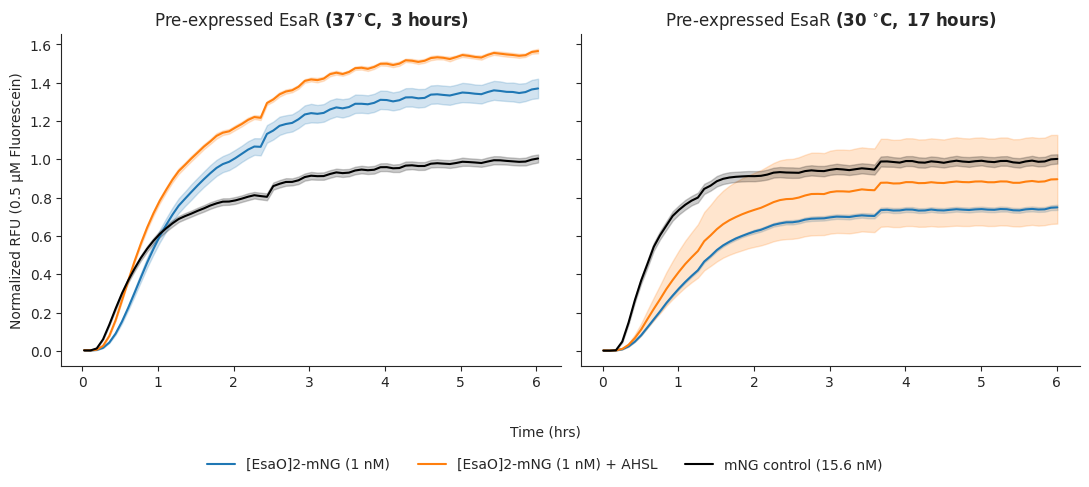

In [ ]:


#!/usr/bin/env python3
"""
Side-by-side plate-reader kinetics with a shared y-axis (seaborn).

Edit the CONFIG block below, then run:
    python plot_panels_seaborn.py
"""
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# =============================================================================
# CONFIG — edit these
# =============================================================================

# One dict per panel, left -> right.
#   file    : CSV path
#   title   : panel title (mathtext $\mathbf{...}$ makes that part bold)
#   include : substring(s) a sample Name must contain to be plotted (None = all)
#   exclude : substring(s) that drop a sample Name (None = nothing dropped)
#   extra   : exact sample Name(s) to add on top of `include` (e.g. the "mNG control (15.6 nM)" control)
PANELS = [
    dict(file="data/normalized_samples_only.csv",
         title=r"Pre-expressed EsaR $\mathbf{(37^{\circ}C,\ 3\ hours)}$",
         include=["[EsaO]2-mNG (1 nM)"], exclude=None, extra=["mNG control (15.6 nM)"]),
    dict(file="normalized_current_run.csv",
         title=r"Pre-expressed EsaR $\mathbf{(30\ ^{\circ}C,\ 17\ hours)}$",
         include=["[EsaO]2-mNG (1 nM)"], exclude=None, extra=["mNG control (15.6 nM)"]),
]

Y_LABEL = "Normalized RFU (0.5 µM Fluorescein)"
X_LABEL = "Time (hrs)"

# What to plot on y:
#   "normalized" -> Data_normalized (fluorescein-calibrated; comparable across days)
#   "raw"        -> raw counts (uses Data_raw if present, otherwise Data)
Y_DATA = "normalized"

# Batch correction to the mNG (-EsaR) control. Each file is multiplied by
# (common mNG level / that file's own mNG level), so the y-axis stays in
# normalized fluorescence units but PURE batch-to-batch offsets cancel.
NORMALISE_TO_REF = True
REFERENCE = "mNG control (15.6 nM)"        # control sample Name in the CSVs
N_LAST_READS = 4         # mNG level = mean of each well's last N reads (steady state)

# Line grouping. Any column of the CSV works, e.g. "Name", "DNA Template (nM)", "AHSL".
HUE = "Name"          # colour
STYLE = None          # line dash (e.g. "AHSL"); None = all solid
PALETTE = "tab10"     # seaborn palette name, or a list of colours
COLOR_OVERRIDES = {"mNG control (15.6 nM)": "black"}   # fix colours for specific hue values

ERRORBAR = "sd"       # "sd", ("ci", 95), "se", or None for no band
SHARE_Y = True
Y_LIM = None          # e.g. (0, 4500); None = auto
X_LIM = None          # e.g. (0, 6)

FIGSIZE = (11, 4.8)
# Legend placement:
#   "shared" -> one legend under the figure (best when there are many lines)
#   "each"   -> a legend inside every panel at LEGEND_LOC (like the reference plot)
LEGEND_MODE = "shared"
LEGEND_LOC = "lower right"   # used when LEGEND_MODE = "each"
LEGEND_NCOL = 3              # used when LEGEND_MODE = "shared"
LEGEND_FONTSIZE = 10

# Fonts — set to match the RFU figure (matplotlib defaults: DejaVu Sans, 10 pt base)
FONT_FAMILY = "DejaVu Sans"
TICK_FONTSIZE = 10
TITLE_FONTSIZE = 12          # panel titles
LABEL_FONTSIZE = 10          # x / y axis labels
OUTFILE = "panels_seaborn.png"
DPI = 200

# =============================================================================


def load_panel(cfg):
    df = pd.read_csv(cfg["file"])

    # Filter sample names
    keep = pd.Series(True, index=df.index)
    if cfg.get("include"):
        keep = df["Name"].apply(lambda n: any(s in n for s in cfg["include"]))
    if cfg.get("exclude"):
        keep &= ~df["Name"].apply(lambda n: any(s in n for s in cfg["exclude"]))
    if cfg.get("extra"):
        keep |= df["Name"].isin(cfg["extra"])
    df = df[keep].copy()

    # y column
    if Y_DATA == "raw":
        df["y"] = df["Data_raw"] if "Data_raw" in df.columns else df["Data"]
    else:
        df["y"] = df["Data_normalized"]

    # Time in hours, aligned across replicate wells (they are read seconds apart)
    df["hours_raw"] = pd.to_timedelta(df["Time"]).dt.total_seconds() / 3600
    df["read_idx"] = df.groupby("Well").cumcount()
    df["hours"] = df.groupby("read_idx")["hours_raw"].transform("mean")

    # Handy grouping column
    df["AHSL"] = df["[AHSL] (uM)"].fillna(0).gt(0).map({True: "+ AHSL", False: "– AHSL"})
    return df


def main():
    sns.set_style("ticks")
    # seaborn's style switches the font list to Arial-first; force the publication font
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": [FONT_FAMILY],
        "font.size": TICK_FONTSIZE,
        "xtick.labelsize": TICK_FONTSIZE,
        "ytick.labelsize": TICK_FONTSIZE,
        "mathtext.fontset": "dejavusans",
        # nothing bold by default: only the \mathbf{...} part of the panel titles
        "font.weight": "normal",
        "axes.titleweight": "normal",
        "axes.labelweight": "normal",
        "figure.titleweight": "normal",
        "figure.labelweight": "normal",
    })
    data = [load_panel(p) for p in PANELS]

    if NORMALISE_TO_REF:
        # steady-state mNG level per file: last N reads per well, then mean over wells
        ref_means = []
        for df in data:
            ref = df[df["Name"] == REFERENCE].sort_values("hours_raw")
            ref_means.append(ref.groupby("Well").tail(N_LAST_READS)["y"].mean())
        common_ref = sum(ref_means) / len(ref_means)   # all files rescaled to this level
        for df, ref_mean in zip(data, ref_means):
            df["y"] = df["y"] * (common_ref / ref_mean)

    # Consistent colours across panels: one colour per hue value, shared by all panels
    hue_order = sorted(pd.concat(d[HUE] for d in data).unique(), key=str) if HUE else None
    if HUE:
        others = [h for h in hue_order if h not in COLOR_OVERRIDES]
        colors = dict(zip(others, sns.color_palette(PALETTE, len(others))))
        colors.update({h: c for h, c in COLOR_OVERRIDES.items() if h in hue_order})
    else:
        colors = None

    fig, axes = plt.subplots(1, len(PANELS), figsize=FIGSIZE, sharey=SHARE_Y, squeeze=False)
    axes = axes[0]

    for ax, cfg, df in zip(axes, PANELS, data):
        sns.lineplot(
            data=df, x="hours", y="y",
            hue=HUE, hue_order=[h for h in hue_order if h in set(df[HUE])] if HUE else None,
            palette=colors, style=STYLE,
            errorbar=ERRORBAR, ax=ax,
        )
        ax.set_title(cfg["title"], fontsize=TITLE_FONTSIZE, fontweight="normal")
        ax.set_xlabel("")
        ax.set_ylabel("")
        if X_LIM:
            ax.set_xlim(X_LIM)
        if ax.get_legend():
            if LEGEND_MODE == "each":
                sns.move_legend(ax, LEGEND_LOC, frameon=False, fontsize=LEGEND_FONTSIZE, title=None)
            else:
                ax.get_legend().remove()

    if Y_LIM:
        axes[0].set_ylim(Y_LIM)
    axes[0].set_ylabel(Y_LABEL, fontsize=LABEL_FONTSIZE, fontweight="normal")
    fig.supxlabel(X_LABEL, fontsize=LABEL_FONTSIZE, fontweight="normal")
    sns.despine(fig)

    if LEGEND_MODE == "shared" and (HUE or STYLE):
        # Collect unique entries across all panels
        seen = {}
        for ax in axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                seen.setdefault(l, h)
        fig.legend(seen.values(), seen.keys(), loc="lower center", ncol=LEGEND_NCOL,
                   frameon=False, fontsize=LEGEND_FONTSIZE, bbox_to_anchor=(0.5, -0.02))
        fig.tight_layout(rect=(0, 0.04 + 0.045 * -(-len(seen) // LEGEND_NCOL), 1, 1))
        fig.supxlabel(X_LABEL, fontsize=LABEL_FONTSIZE, fontweight="normal",
                      y=0.03 + 0.045 * -(-len(seen) // LEGEND_NCOL))
    else:
        fig.tight_layout()
    fig.savefig(OUTFILE, dpi=DPI, bbox_inches="tight")

if __name__ == "__main__":
    main()

## Plot comparison summary plot normalized to mNG control

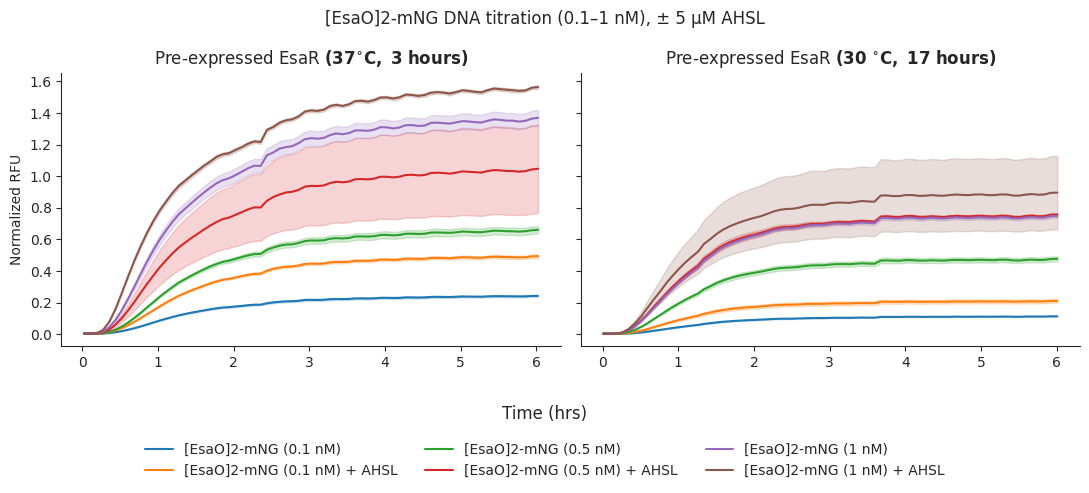

In [ ]:
#| label: cn-20260926-fig1

#!/usr/bin/env python3
"""
Side-by-side plate-reader kinetics with a shared y-axis (seaborn),
batch-corrected to the mNG (-EsaR) control. The mNG control is used for the
correction but is not drawn.

Edit the CONFIG block below, then run:
    python plot_panels_normalised.py
"""
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# =============================================================================
# CONFIG — edit these
# =============================================================================

PANELS = [
    dict(file="data/normalized_samples_only.csv",
         title=r"Pre-expressed EsaR $\mathbf{(37^{\circ}C,\ 3\ hours)}$",
         include=["[EsaO]2-mNG"], exclude=None, extra=["mNG control (15.6 nM)"]),
    dict(file="normalized_current_run.csv",
         title=r"Pre-expressed EsaR $\mathbf{(30\ ^{\circ}C,\ 17\ hours)}$",
         include=["[EsaO]2-mNG"], exclude=None, extra=["mNG control (15.6 nM)"]),
]

SUPTITLE = "[EsaO]2-mNG DNA titration (0.1–1 nM), ± 5 µM AHSL"
Y_LABEL = "Normalized RFU"
X_LABEL = "Time (hrs)"

Y_DATA = "normalized"

REFERENCE = "mNG control (15.6 nM)"
N_LAST_READS = 4

HUE = "Name"
STYLE = None
PALETTE = "tab10"

ERRORBAR = "sd"
SHARE_Y = True
Y_LIM = None
X_LIM = None

FIGSIZE = (11, 4.8)
LEGEND_MODE = "shared"
LEGEND_LOC = "lower right"
LEGEND_NCOL = 3
LEGEND_FONTSIZE = 10
OUTFILE = "panels_seaborn_mNG_normalised.png"
DPI = 200

# =============================================================================


def load_panel(cfg):
    df = pd.read_csv(cfg["file"])

    keep = pd.Series(True, index=df.index)
    if cfg.get("include"):
        keep = df["Name"].apply(lambda n: any(s in n for s in cfg["include"]))
    if cfg.get("exclude"):
        keep &= ~df["Name"].apply(lambda n: any(s in n for s in cfg["exclude"]))
    if cfg.get("extra"):
        keep |= df["Name"].isin(cfg["extra"])
    df = df[keep].copy()

    if Y_DATA == "raw":
        df["y"] = df["Data_raw"] if "Data_raw" in df.columns else df["Data"]
    else:
        df["y"] = df["Data_normalized"]

    df["hours_raw"] = pd.to_timedelta(df["Time"]).dt.total_seconds() / 3600
    df["read_idx"] = df.groupby("Well").cumcount()
    df["hours"] = df.groupby("read_idx")["hours_raw"].transform("mean")

    df["AHSL"] = df["[AHSL] (uM)"].fillna(0).gt(0).map({True: "+ AHSL", False: "– AHSL"})
    return df


def normalise_to_reference(data):
    ref_means = []
    for df in data:
        ref = df[df["Name"] == REFERENCE].sort_values("hours_raw")
        ref_means.append(ref.groupby("Well").tail(N_LAST_READS)["y"].mean())
    common_ref = sum(ref_means) / len(ref_means)

    out = []
    for df, ref_mean in zip(data, ref_means):
        df = df.copy()
        df["y"] = df["y"] * (common_ref / ref_mean)
        out.append(df)
    return out


def main():
    data = [load_panel(p) for p in PANELS]
    data = normalise_to_reference(data)
    data = [df[df["Name"] != REFERENCE].copy() for df in data]

    hue_order = sorted(pd.concat(d[HUE] for d in data).unique(), key=str) if HUE else None
    colors = dict(zip(hue_order, sns.color_palette(PALETTE, len(hue_order)))) if HUE else None

    fig, axes = plt.subplots(1, len(PANELS), figsize=FIGSIZE, sharey=SHARE_Y, squeeze=False)
    axes = axes[0]

    for ax, cfg, df in zip(axes, PANELS, data):
        sns.lineplot(
            data=df, x="hours", y="y",
            hue=HUE, hue_order=[h for h in hue_order if h in set(df[HUE])] if HUE else None,
            palette=colors, style=STYLE,
            errorbar=ERRORBAR, ax=ax,
        )
        ax.set_title(cfg["title"])
        ax.set_xlabel("")
        ax.set_ylabel("")
        if X_LIM:
            ax.set_xlim(X_LIM)
        if ax.get_legend():
            if LEGEND_MODE == "each":
                sns.move_legend(ax, LEGEND_LOC, frameon=False, fontsize=LEGEND_FONTSIZE, title=None)
            else:
                ax.get_legend().remove()

    if Y_LIM:
        axes[0].set_ylim(Y_LIM)
    axes[0].set_ylabel(Y_LABEL)
    fig.supxlabel(X_LABEL)
    fig.suptitle(SUPTITLE)
    sns.despine(fig)

    if LEGEND_MODE == "shared" and (HUE or STYLE):
        seen = {}
        for ax in axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                seen.setdefault(l, h)
        fig.legend(seen.values(), seen.keys(), loc="lower center", ncol=LEGEND_NCOL,
                   frameon=False, fontsize=LEGEND_FONTSIZE, bbox_to_anchor=(0.5, -0.02))
        fig.tight_layout(rect=(0, 0.04 + 0.045 * -(-len(seen) // LEGEND_NCOL), 1, 1))
        fig.supxlabel(X_LABEL, y=0.03 + 0.045 * -(-len(seen) // LEGEND_NCOL))
    else:
        fig.tight_layout()
    fig.savefig(OUTFILE, dpi=DPI, bbox_inches="tight")
    plt.show()


if __name__ == "__main__":
    main()

## Plot fold change comparison (mNG normalization not neccessary when calculating fold change)

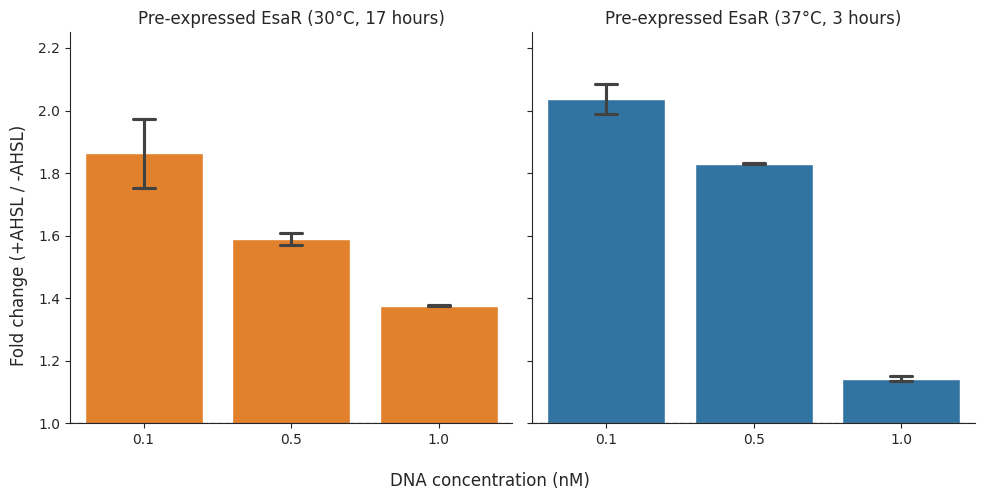

In [ ]:
#| label: cn-20260926-fig2

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# =============================================================================
# CONFIG
# =============================================================================
DATASETS = {
    "Pre-expressed EsaR (30°C, 17 hours)": "normalized_current_run.csv",
    "Pre-expressed EsaR (37°C, 3 hours)": "data/normalized_samples_only.csv",
}
CONSTRUCT = "[EsaO]2-mNG"
DNA_CONCS = ["0.1", "0.5", "1"]
N_LAST_READS = 4
Y_COL = "Data_normalized"

PALETTE = ["tab:orange", "tab:blue"]

X_LABEL = "DNA concentration (nM)"
Y_LABEL = "Fold change (+AHSL / -AHSL)"
OUTFILE = "fold_change_comparison.png"

# Low-outlier +AHSL wells to exclude: (EsaR prep, DNA_conc)
EXCLUDE_LOWEST_AHSL = {
    ("Pre-expressed EsaR (30°C, 17 hours)", "1"),
    ("Pre-expressed EsaR (37°C, 3 hours)", "0.5"),
}
# =============================================================================


def steady_state_values(path, name, n_reads=N_LAST_READS):
    df = pd.read_csv(path)
    df["Time_hrs"] = pd.to_timedelta(df["Time"]).dt.total_seconds() / 3600
    tail = (df.sort_values("Time_hrs").groupby(["Name", "Well"])
              .tail(n_reads).groupby(["Name", "Well"])[Y_COL].mean())
    return tail[name].values


def drop_lowest(values):
    values = list(values)
    values.remove(min(values))
    return values


# ----------------------------------------------------------------------------
# Per-well fold change (+AHSL / mean of -AHSL), for each prep and concentration
# ----------------------------------------------------------------------------
rows = []
for label, path in DATASETS.items():
    for conc in DNA_CONCS:
        base_name = f"{CONSTRUCT} ({conc} nM)"
        ahsl_name = f"{CONSTRUCT} ({conc} nM) + AHSL"
        base_vals = steady_state_values(path, base_name)
        ahsl_vals = steady_state_values(path, ahsl_name)
        if (label, conc) in EXCLUDE_LOWEST_AHSL:
            ahsl_vals = drop_lowest(ahsl_vals)
        for v in ahsl_vals / base_vals.mean():
            rows.append({"EsaR prep": label, "DNA_conc_nM": float(conc), "Fold_change": v})

fold_summary = pd.DataFrame(rows)

# ----------------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------------
preps = list(DATASETS.keys())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharey=True)

subset_1 = fold_summary[fold_summary["EsaR prep"] == preps[0]]
sns.barplot(data=subset_1, x="DNA_conc_nM", y="Fold_change", color=PALETTE[0], errorbar="sd", capsize=0.15, ax=ax1)
ax1.set(title=preps[0], xlabel="", ylabel="")
ax1.axhline(1, color="grey", linestyle="--", linewidth=1)

subset_2 = fold_summary[fold_summary["EsaR prep"] == preps[1]]
sns.barplot(data=subset_2, x="DNA_conc_nM", y="Fold_change", color=PALETTE[1], errorbar="sd", capsize=0.15, ax=ax2)
ax2.set(title=preps[1], xlabel="", ylabel="")
ax2.axhline(1, color="grey", linestyle="--", linewidth=1)

ax1.set_ylim(1, 2.25)

fig.supxlabel(X_LABEL)
fig.supylabel(Y_LABEL)

sns.despine(fig)
fig.tight_layout()
fig.savefig(OUTFILE, dpi=200, bbox_inches="tight")
plt.show()

## Plot steady-state yield normalized to mNG control (mNG normalization check included)

mNG reference mean per file:
 Pre-expressed EsaR (30°C, 17 hours)   0.87
Pre-expressed EsaR (37°C, 3 hours)    1.11
Common mNG level: 0.994
Scale factors:
 Pre-expressed EsaR (30°C, 17 hours)   1.14
Pre-expressed EsaR (37°C, 3 hours)    0.89


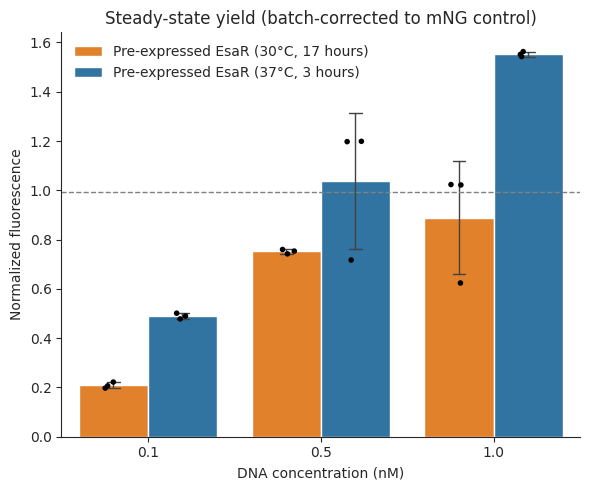

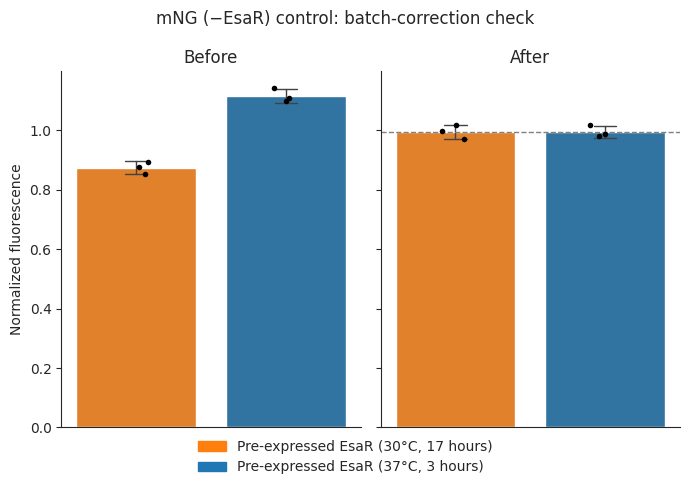

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# =============================================================================
# CONFIG
# =============================================================================
DATASETS = {
    "Pre-expressed EsaR (30°C, 17 hours)": "normalized_current_run.csv",
    "Pre-expressed EsaR (37°C, 3 hours)": "normalized_samples_only.csv",
}
CONSTRUCT = "[EsaO]2-mNG"
DNA_CONCS = ["0.1", "0.5", "1"]
REFERENCE = "mNG control (15.6 nM)"
N_LAST_READS = 4
Y_COL = "Data_normalized"

PALETTE = ["tab:orange", "tab:blue"]


TITLE = "Steady-state yield (batch-corrected to mNG control)"
X_LABEL = "DNA concentration (nM)"
Y_LABEL = "Normalized fluorescence"
ERRORBAR = "sd"
SHOW_POINTS = True
FIGSIZE = (6, 5)
OUTFILE = "steady_state_yield_batch_corrected.png"
DPI = 200
# =============================================================================

PREP_COLORS = dict(zip(DATASETS, PALETTE))


def steady_state_yield_per_well(path, n_reads=N_LAST_READS):
    df = pd.read_csv(path)
    df["Time_hrs"] = pd.to_timedelta(df["Time"]).dt.total_seconds() / 3600
    return (df.sort_values("Time_hrs").groupby(["Name", "Well"])
              .tail(n_reads).groupby(["Name", "Well"])[Y_COL].mean().reset_index())


# ----------------------------------------------------------------------------
# Batch-correction factors from the mNG (-EsaR) control
# ----------------------------------------------------------------------------
wells_by_prep = {label: steady_state_yield_per_well(path) for label, path in DATASETS.items()}
ref_means = pd.Series({label: w.loc[w["Name"] == REFERENCE, Y_COL].mean()
                       for label, w in wells_by_prep.items()})
common_ref = ref_means.mean()                 # all files are rescaled to this mNG level
scale = common_ref / ref_means                # multiplicative factor per file

print("mNG reference mean per file:\n", ref_means.round(3).to_string())
print(f"Common mNG level: {common_ref:.3f}")
print("Scale factors:\n", scale.round(3).to_string())

# ----------------------------------------------------------------------------
# Compute corrected per-well values
# ----------------------------------------------------------------------------
rows = []
ref_rows = []
for label, wells in wells_by_prep.items():
    for v in wells.loc[wells["Name"] == REFERENCE, Y_COL]:
        ref_rows.append({"EsaR prep": label, "Raw": v, "Corrected": v * scale[label]})

    for conc in DNA_CONCS:
        name = f"{CONSTRUCT} ({conc} nM) + AHSL"
        for v in wells.loc[wells["Name"] == name, Y_COL]:
            rows.append({"EsaR prep": label, "DNA_conc_nM": float(conc),
                         "Yield": v * scale[label]})

yield_wells = pd.DataFrame(rows)
ref_wells = pd.DataFrame(ref_rows)

# ----------------------------------------------------------------------------
# Figure 1: batch-corrected yield
# ----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=FIGSIZE)
kw = dict(data=yield_wells, x="DNA_conc_nM", y="Yield", hue="EsaR prep",
          hue_order=list(DATASETS), ax=ax)
sns.barplot(**kw, palette=PREP_COLORS, errorbar=ERRORBAR, capsize=0.15,
            err_kws={"linewidth": 1})
if SHOW_POINTS:
    sns.stripplot(**kw, palette={p: "black" for p in DATASETS},
                  dodge=True, size=4, legend=False)

ax.axhline(common_ref, color="grey", linestyle="--", linewidth=1)   # mNG (-EsaR) level
ax.set(xlabel=X_LABEL, ylabel=Y_LABEL)
ax.set_title(TITLE)
ax.legend(title=None, frameon=False)

sns.despine(fig)
fig.tight_layout()
fig.savefig(OUTFILE, dpi=DPI, bbox_inches="tight")
plt.show()

# ----------------------------------------------------------------------------
# Figure 2: mNG control before vs after batch correction
# ----------------------------------------------------------------------------
fig2, (axA, axB) = plt.subplots(1, 2, figsize=(7, 4.5), sharey=True)
fig2.suptitle("mNG (−EsaR) control: batch-correction check")

for ax_, col, title in [(axA, "Raw", "Before"), (axB, "Corrected", "After")]:
    sns.barplot(data=ref_wells, x="EsaR prep", y=col, hue="EsaR prep",
                order=list(DATASETS), hue_order=list(DATASETS), palette=PREP_COLORS,
                errorbar=ERRORBAR, capsize=0.15, err_kws={"linewidth": 1},
                legend=False, ax=ax_)
    sns.stripplot(data=ref_wells, x="EsaR prep", y=col, order=list(DATASETS),
                  color="black", size=4, ax=ax_)
    ax_.set(title=title, xlabel="", ylabel="")
    ax_.set_xticks([])

axA.set_ylabel(Y_LABEL)
axB.axhline(common_ref, color="grey", linestyle="--", linewidth=1)

handles = [plt.Rectangle((0, 0), 1, 1, color=PREP_COLORS[p]) for p in DATASETS]
fig2.legend(handles, list(DATASETS), loc="lower center", ncol=1,
            frameon=False, bbox_to_anchor=(0.5, -0.08))

sns.despine(fig2)
fig2.tight_layout()
fig2.savefig("mNG_control_check.png", dpi=DPI, bbox_inches="tight")
plt.show()

## Plot steady state yield comparison normalized to mNG control (Final)

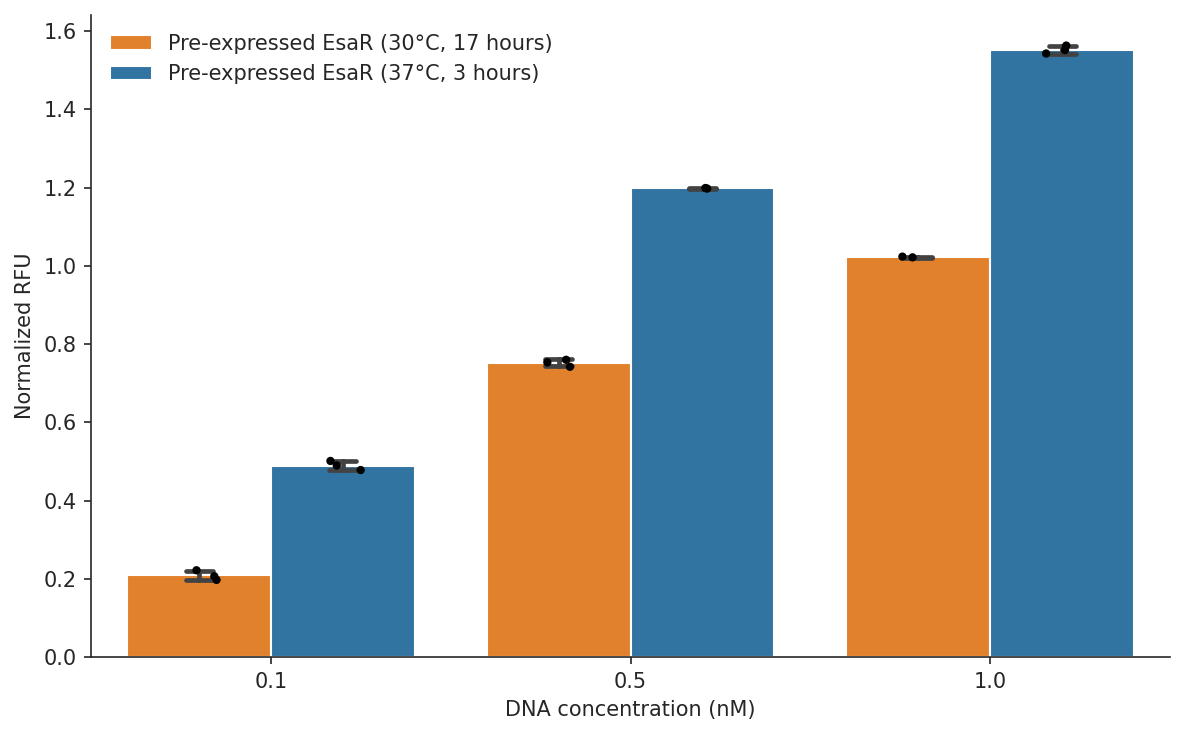

In [ ]:
#| label: cn-20260926-fig3

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# =============================================================================
# CONFIG
# =============================================================================
DATASETS = {
    "Pre-expressed EsaR (30°C, 17 hours)": "normalized_current_run.csv",
    "Pre-expressed EsaR (37°C, 3 hours)": "normalized_samples_only.csv",
}
CONSTRUCT = "[EsaO]2-mNG"
DNA_CONCS = ["0.1", "0.5", "1"]
REFERENCE = "mNG control (15.6 nM)"
N_LAST_READS = 4
Y_COL = "Data_normalized"

PALETTE = ["tab:orange", "tab:blue"]

X_LABEL = "DNA concentration (nM)"
Y_LABEL = "Normalized RFU"
ERRORBAR = "sd"
SHOW_POINTS = True
FIGSIZE = (8, 5)
OUTFILE = "steady_state_yield_batch_corrected.png"
DPI = 200

# Low-outlier +AHSL wells to exclude: (EsaR prep, DNA_conc)
EXCLUDE_LOWEST_AHSL = {
    ("Pre-expressed EsaR (30°C, 17 hours)", "1"),
    ("Pre-expressed EsaR (37°C, 3 hours)", "0.5"),
}
# =============================================================================

PREP_COLORS = dict(zip(DATASETS, PALETTE))


def steady_state_yield_per_well(path, n_reads=N_LAST_READS):
    df = pd.read_csv(path)
    df["Time_hrs"] = pd.to_timedelta(df["Time"]).dt.total_seconds() / 3600
    return (df.sort_values("Time_hrs").groupby(["Name", "Well"])
              .tail(n_reads).groupby(["Name", "Well"])[Y_COL].mean().reset_index())


def drop_lowest(values):
    values = list(values)
    values.remove(min(values))
    return values


# ----------------------------------------------------------------------------
# Batch-correction factors from the mNG (-EsaR) control
# ----------------------------------------------------------------------------
wells_by_prep = {label: steady_state_yield_per_well(path) for label, path in DATASETS.items()}
ref_means = pd.Series({label: w.loc[w["Name"] == REFERENCE, Y_COL].mean()
                       for label, w in wells_by_prep.items()})
scale = ref_means.mean() / ref_means   # rescale every file to the average mNG level

# ----------------------------------------------------------------------------
# Corrected per-well values
# ----------------------------------------------------------------------------
rows = []
for label, wells in wells_by_prep.items():
    for conc in DNA_CONCS:
        name = f"{CONSTRUCT} ({conc} nM) + AHSL"
        vals = wells.loc[wells["Name"] == name, Y_COL].values * scale[label]
        if (label, conc) in EXCLUDE_LOWEST_AHSL:
            vals = drop_lowest(vals)
        for v in vals:
            rows.append({"EsaR prep": label, "DNA_conc_nM": float(conc), "Yield": v})

yield_wells = pd.DataFrame(rows)

# ----------------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=150)
kw = dict(data=yield_wells, x="DNA_conc_nM", y="Yield", hue="EsaR prep",
          hue_order=list(DATASETS), ax=ax)
sns.barplot(**kw, palette=PREP_COLORS, errorbar=ERRORBAR, capsize=0.15)
if SHOW_POINTS:
    sns.stripplot(**kw, palette={p: "black" for p in DATASETS},
                  dodge=True, size=4, legend=False)

ax.set(xlabel=X_LABEL, ylabel=Y_LABEL)
ax.legend(title=None, frameon=False)

sns.despine(fig)
fig.tight_layout()
fig.savefig(OUTFILE, dpi=DPI, bbox_inches="tight")
plt.show()

If you want to change the time window over which you calculate the average, you can use the `window` argument:

In [ ]:
# data = data.normalize('10 uM HPTS', window=pd.Timedelta("2.5h"))

## Kinetic Analysis

See the [DevNote](https://devnotes.nucleus.engineering/articles/Newman-20260421) on kinetic analysis for more details.

**Metrics extracted:**

  - **Maximum velocity**: Maximum rate of fluorescence increase (slope at inflection point)
  - **Lag time**: Time to reach the exponential phase
  - **Steady-state**: Final fluorescence level
  - **Time-to-completion**: Time it takes to reach 95% of asymptote
  - **Drift**: Rate of signal decay or increase after steady-state
  - **R²**: Goodness of fit; "Good Fit" is `True` if $R^2 \geq 0.95$

In [ ]:
# Perform kinetic analysis using sigmoid_drift model
kinetics = data.fit_kinetics()

In [ ]:
kinetics.summary

,Well,Name,Max Velocity,Max Velocity Time,Lag Time,Steady State,Completion Time,Completion Threshold,Drift,Fit Function,R^2,Good Fit,Normalized to
0,B2,mNG control (15.6 nM),0.92,0 days 00:32:25,0 days 00:02:38,0.87,0 days 01:16:16,0.95,0.02,sigmoid_drift,0.99,True,Fluorescein 0.5uM
1,B3,mNG control (15.6 nM),0.90,0 days 00:32:42,0 days 00:02:49,0.85,0 days 01:16:43,0.95,0.02,sigmoid_drift,1.00,True,Fluorescein 0.5uM
2,B4,mNG control (15.6 nM),0.85,0 days 00:32:37,0 days 00:02:01,0.83,0 days 01:17:41,0.95,0.02,sigmoid_drift,1.00,True,Fluorescein 0.5uM
3,D2,[EsaO]2-mNG (0.1 nM),0.06,0 days 01:02:11,0 days 00:14:37,0.09,0 days 02:12:11,0.95,0.00,sigmoid_drift,1.00,True,Fluorescein 0.5uM
4,D3,[EsaO]2-mNG (0.1 nM),0.06,0 days 01:03:26,0 days 00:16:17,0.09,0 days 02:12:51,0.95,0.00,sigmoid_drift,1.00,True,Fluorescein 0.5uM
5,D4,[EsaO]2-mNG (0.1 nM),0.05,0 days 01:04:00,0 days 00:11:26,0.09,0 days 02:21:25,0.95,0.00,sigmoid_drift,1.00,True,Fluorescein 0.5uM
6,D6,[EsaO]2-mNG (0.1 nM) + AHSL,0.12,0 days 00:59:12,0 days 00:11:24,0.18,0 days 02:09:33,0.95,0.00,sigmoid_drift,1.00,True,Fluorescein 0.5uM
7,D7,[EsaO]2-mNG (0.1 nM) + AHSL,0.12,0 days 00:59:43,0 days 00:13:58,0.17,0 days 02:07:05,0.95,0.00,sigmoid_drift,1.00,True,Fluorescein 0.5uM
8,D8,[EsaO]2-mNG (0.1 nM) + AHSL,0.10,0 days 01:00:05,0 days 00:09:54,0.16,0 days 02:13:59,0.95,0.00,sigmoid_drift,1.00,True,Fluorescein 0.5uM
9,D10,[EsaO]2-mNG (0.5 nM),0.24,0 days 01:01:20,0 days 00:11:21,0.38,0 days 02:14:54,0.95,0.01,sigmoid_drift,1.00,True,Fluorescein 0.5uM


## Visualize Fits

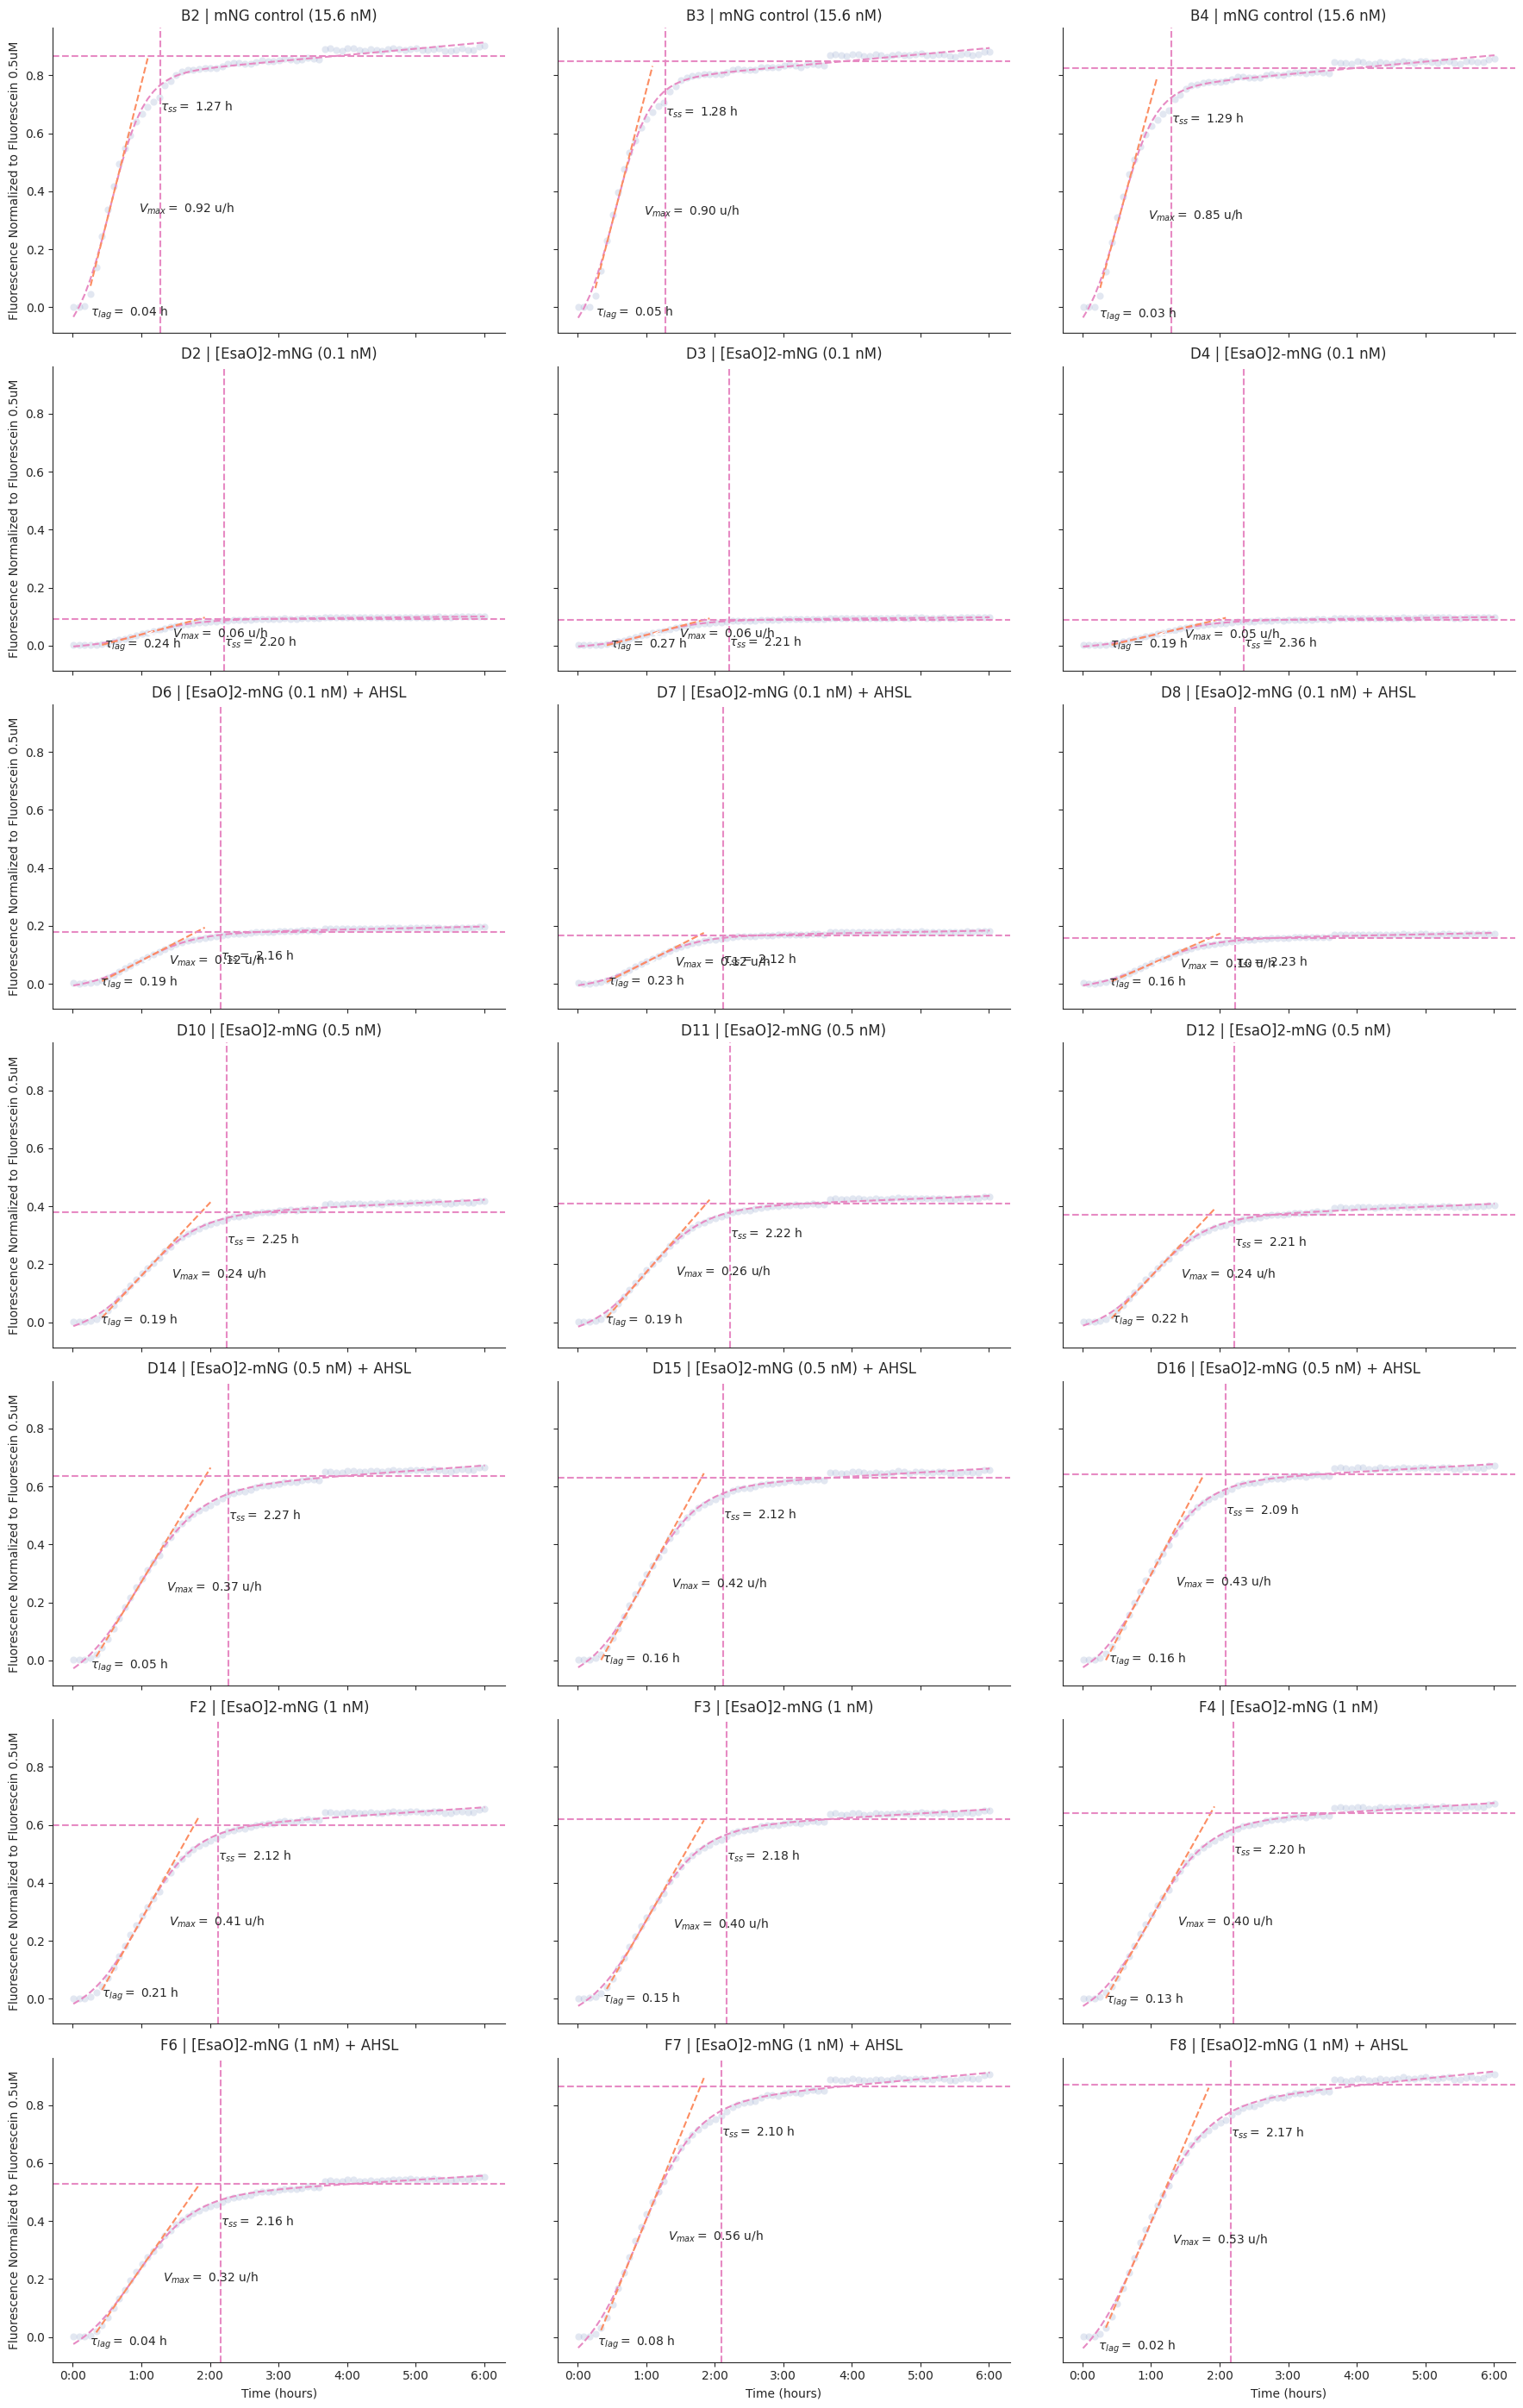

In [ ]:
g = kinetics.plot(col="Well")
# g = kinetics.plot() # call this to visualize across replicates

## Summary Plots

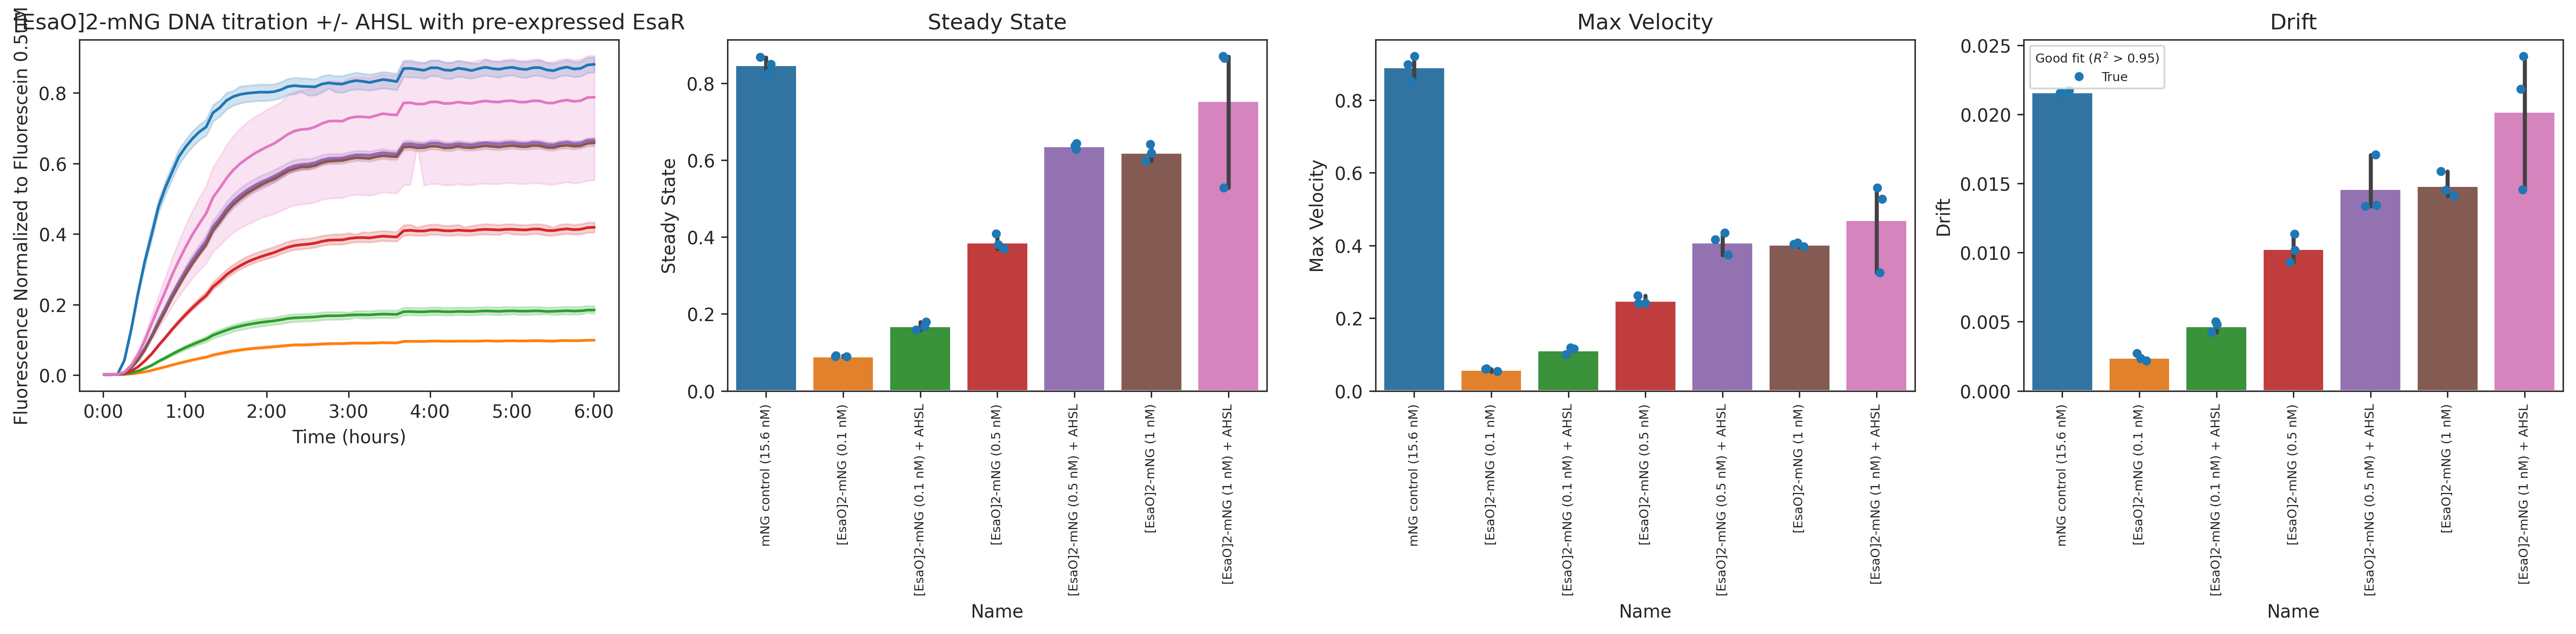

In [ ]:
g = kinetics.plot_summary()

---

## Key Metrics Explained

### 1. **Steady-State Level** (`Steady State, Data`)
- The final fluorescence value reached by the reaction
- Represents the total amount of protein produced
- Higher values indicate greater expression yield

### 2. **Maximum Velocity** (`Velocity, Max`)
- The steepest slope of the fluorescence curve (at the inflection point)
- Units: RFU per second
- Reflects the peak rate of protein synthesis
- Sensitive to enzyme activity, substrate availability, and reaction conditions

### 3. **Lag Time** (`Lag, Time`)
- Time before exponential fluorescence increase begins
- May reflect time for ribosome assembly or initial translation steps
- Shorter lag times suggest faster reaction initiation

### 4. **Drift** (`Fit, drift`)
- Rate of fluorescence change after reaching steady-state
- Positive drift: continued synthesis or aggregation
- Negative drift: photobleaching, protein degradation, or quenching
- Units: RFU per second

### 5. **R² Value** (`Fit, R^2`)
- Goodness of fit (0 to 1, higher is better)
- R² > 0.98 indicates excellent fit
- Poor fits may indicate noisy data, overflow errors, or non-sigmoid kinetics

---

## Tips and Troubleshooting

- **Overflow errors:** Wells with `OVRFLW` or `NaN` values are automatically excluded from fitting
- **Poor fits (low R²):** Inspect raw curves for anomalies (bubbles, evaporation, pipetting errors)
- **Drift:** Sometimes seen in kinetics curves; use `sigmoid_drift` model
- **Multiple replicates:** Always include technical replicates and report error bars
- **Comparing conditions:** Normalize or blank data consistently across all samples

---

## Next Steps

- Export kinetics results: `pr.export_kinetics(kinetics, 'results.csv')`
- Statistical analysis: Use `scipy.stats` or `statsmodels` for ANOVA/t-tests
- Parameter optimization: Vary Mg²⁺, K⁺, or other conditions to maximize Vmax or steady-state
- Mechanistic modeling: Fit ODE models to extract biological rate constants